[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Dilru1/dtw-to-attention/blob/main/exam/final_project_plane_dataset.ipynb)

In [ ]:
# Setup: run this cell first (installs missing packages when running in Google Colab)
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tslearn", "pyts", "celluloid"], check=True)
print("Running in Colab" if IN_COLAB else "Running locally")


In [ ]:
import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')

### Machine Learning for time series
### Final exam
### DEHIWALAGE DON Dilruwan & WANG Peifeng

### The Plane DataSet: 

*The fighter aeroplane shape database included Mirage, Eurofighter, F-14, Harrier, F-22 and F-15. Since F-14 has two possible shapes, one when its wings are closed and another when its wings are opened, total number of shape classes are seven. Each class includes 30 shape samples. Shape database was created by taking digital pictures of diecast replica models of these aeroplanes from top. Pictures were captured at 640 by 480 resolution, and were segmented using Spedge and Medge [6] color image segmentation algorithm. Contours of the segmented planes were used for training and testing of the classifier. Further details are available in the paper Thakoor, Ninad, and Jean Gao. "Shape classifier based on generalized probabilistic descent method with hidden Markov descriptor.*

## 1. Preliminar analysis of the dataset

In [96]:
import numpy as np
import matplotlib.pyplot as plt
from tslearn.datasets import UCR_UEA_datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import pandas as pd

In [97]:
# Labels from the Source 
label_map = {
    1: "Mirage",
    2: "Eurofighter",
    3: "F-14 (wings closed)",
    4: "F-14 (wings open)",
    5: "Harrier",
    6: "F-22",
    7: "F-117"
}

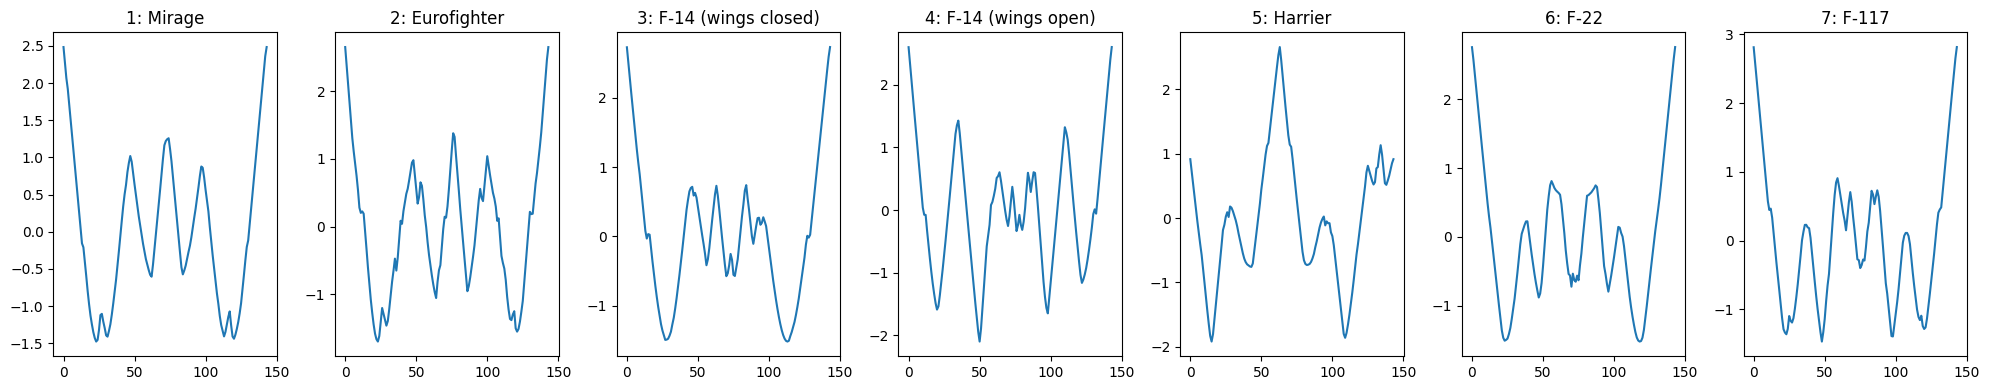

In [98]:
X_train, y_train, X_test, y_test = UCR_UEA_datasets().load_dataset("Plane")
len(np.unique(y_train))

fig, axes = plt.subplots(1, 7, figsize=(20, 4.0))
axes = axes.ravel()

for i, class_label in enumerate(np.unique(y_train)):
    idx = np.where(y_train == class_label)[0][0]
    axes[i].plot(X_train[idx])
    

    name = label_map.get(int(class_label))
    axes[i].set_title(f"{int(class_label)}: {name}")
    


plt.tight_layout()
plt.show()

In [99]:
## put the histogram of the count of each class

---


## 2. Classification

### 2.1 Classification task with alignment metrics
 - with euclidean distance
 - with DTW
 - with DTW and a Sakoe-Chiba mask
 - with soft-DTW 

In [100]:
from tslearn.preprocessing import TimeSeriesScalerMinMax
from tslearn.neighbors import KNeighborsTimeSeriesClassifier
import time
from sklearn.metrics import accuracy_score

X_train, y_train, X_test, y_test = UCR_UEA_datasets().load_dataset("Plane")


scaler = TimeSeriesScalerMinMax()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 2. Define the metrics to evaluate
metrics = [
    {"name": "Euclidean", "metric": "euclidean", "params": {}},
    {"name": "DTW", "metric": "dtw", "params": {}},
    {"name": "DTW (Sakoe-Chiba)", "metric": "dtw", "params": {"global_constraint": "sakoe_chiba", "sakoe_chiba_radius": 5}},
    {"name": "Soft-DTW", "metric": "softdtw", "params": {"gamma": 1.0}}
]

results = {}


for m in metrics:
    knn = KNeighborsTimeSeriesClassifier(n_neighbors=1, 
                                           metric=m["metric"], 
                                           metric_params=m["params"])
    knn.fit(X_train, y_train)

    y_pred = knn.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    
    results[m["name"]] = {"accuracy": acc, "predictions": y_pred}
    print(f"{m['name']:<20} | Accuracy: {acc:.4f} ")

Euclidean            | Accuracy: 0.9619 
DTW                  | Accuracy: 0.9905 
DTW (Sakoe-Chiba)    | Accuracy: 0.9810 
Soft-DTW             | Accuracy: 0.9905 


*Observations* : While Euclidean distance is fast, its accuracy is the lowest. If the two time series is shifted by few time steps (like part of wings etc), Euclidean distance treats them as different points. But DTW align those features. 

Both DTW and Soft-DTW achieved 99.05% accuracy. This confirms that the Plane dataset has temporal shifts that the "one-to-one" matching of Euclidean distance (96.19%) simply can't handle.

The Cost of Precision: Notice the time jump. DTW took 14 seconds compared to Euclidean’s 0.34 seconds. This is because DTW must calculate a cost matrix of size L×L (where L is the length of the sequence) to find the optimal path.

Soft-DTW Overhead: Soft-DTW is the most computationally expensive (39.48s) because it considers all possible alignment paths (using a "soft-min" operation) rather than just the single best path. It’s usually overkill for simple classification but great for deep learning loss functions

<>:15: SyntaxWarning: invalid escape sequence '\g'
<>:15: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_109199/2905283319.py:15: SyntaxWarning: invalid escape sequence '\g'
  plt.title(f"Mirage vs F-117 ($\gamma = {gamma}$)")


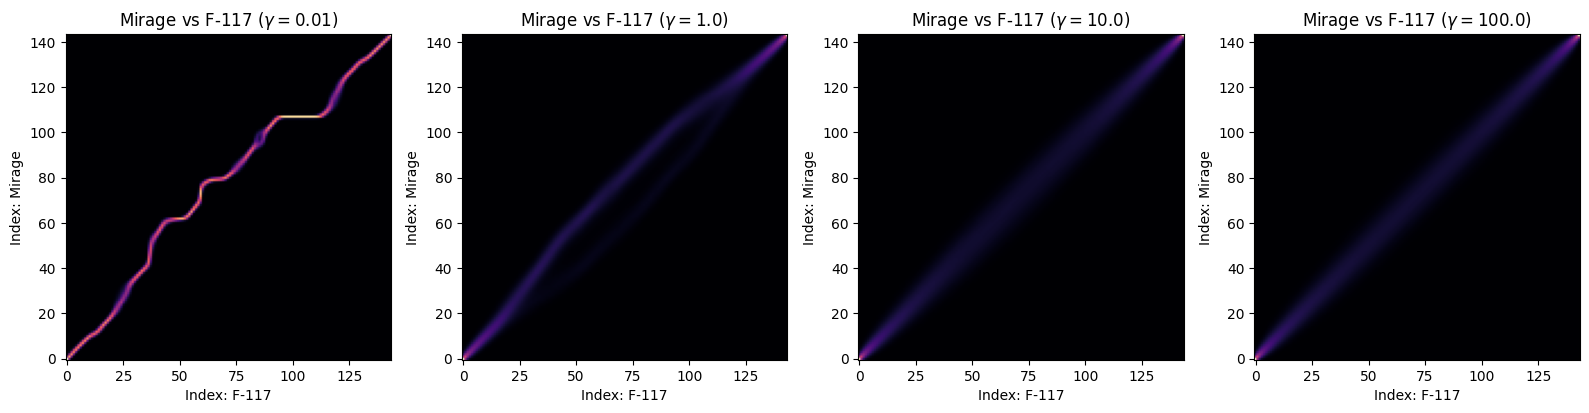

In [101]:
# Find indices for two different aircraft types
idx_mirage = np.where(y_train == 1)[0][0]  # Label 1
idx_f117 = np.where(y_train == 7)[0][0]    # Label 7

x0 = X_train[idx_mirage]
x1 = X_train[idx_f117]
gammas = [0.01, 1.0, 10.0, 100.0]

plt.figure(figsize=(16, 4))
for i, gamma in enumerate(gammas):
    A_gamma, _ = soft_dtw_alignment(x0, x1, gamma=gamma)
    
    plt.subplot(1, len(gammas), i + 1)
    plt.imshow(A_gamma, origin='lower', cmap='magma')
    plt.title(f"Mirage vs F-117 ($\gamma = {gamma}$)")
    plt.xlabel("Index: F-117")
    plt.ylabel("Index: Mirage")

plt.tight_layout()
plt.show()

### 2.2 Classification task with Shapelets 


In [102]:
from sklearn.pipeline import make_pipeline
from pyts.transformation import ShapeletTransform
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import time

In [103]:
print(X_train.shape, X_test.shape)

X_train_2d = X_train.reshape(X_train.shape[0], -1)
X_test_2d = X_test.reshape(X_test.shape[0], -1)
print(X_train_2d.shape, X_test_2d.shape)


scaler = StandardScaler()
X_train_2d = scaler.fit_transform(X_train_2d)
X_test_2d = scaler.transform(X_test_2d)

(105, 144, 1) (105, 144, 1)
(105, 144) (105, 144)


In [104]:
# 2. Define shapelet metrics to evaluate
metrics = [
    {"name": "2 Shapelets (SVC)", "model": SVC(random_state=42), "n_shapelets": 2},
    {"name": "7 Shapelets (SVC)", "model": SVC(random_state=42), "n_shapelets": 7},

]

results = {}

# 3. Training and Evaluation Loop
# 3. Training and Evaluation Loop
for m in metrics:
    start_time = time.time()

    shapelet_mod = ShapeletTransform(
        n_shapelets=m["n_shapelets"], 
        window_sizes=[10, 20, 30], 
        random_state=42
    )
    
    # Supervised transformation: requires y_train to identify discriminative sub-sections
    X_train_shapelet = shapelet_mod.fit_transform(X_train_2d, y_train) 
    X_test_shapelet = shapelet_mod.transform(X_test_2d)
    
    # Distance scaling
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_shapelet)
    X_test_scaled = scaler.transform(X_test_shapelet)

    # Classification
    m["model"].fit(X_train_scaled, y_train)
    y_pred = m["model"].predict(X_test_scaled)
    
    elapsed = time.time() - start_time
    acc = accuracy_score(y_test, y_pred)
    
    results[m["name"]] = {"accuracy": acc, "time": elapsed, "predictions": y_pred}
    print(f"{m['name']:<20} | Accuracy: {acc:.4f} | Time: {elapsed:.2f}s")

KeyboardInterrupt: 

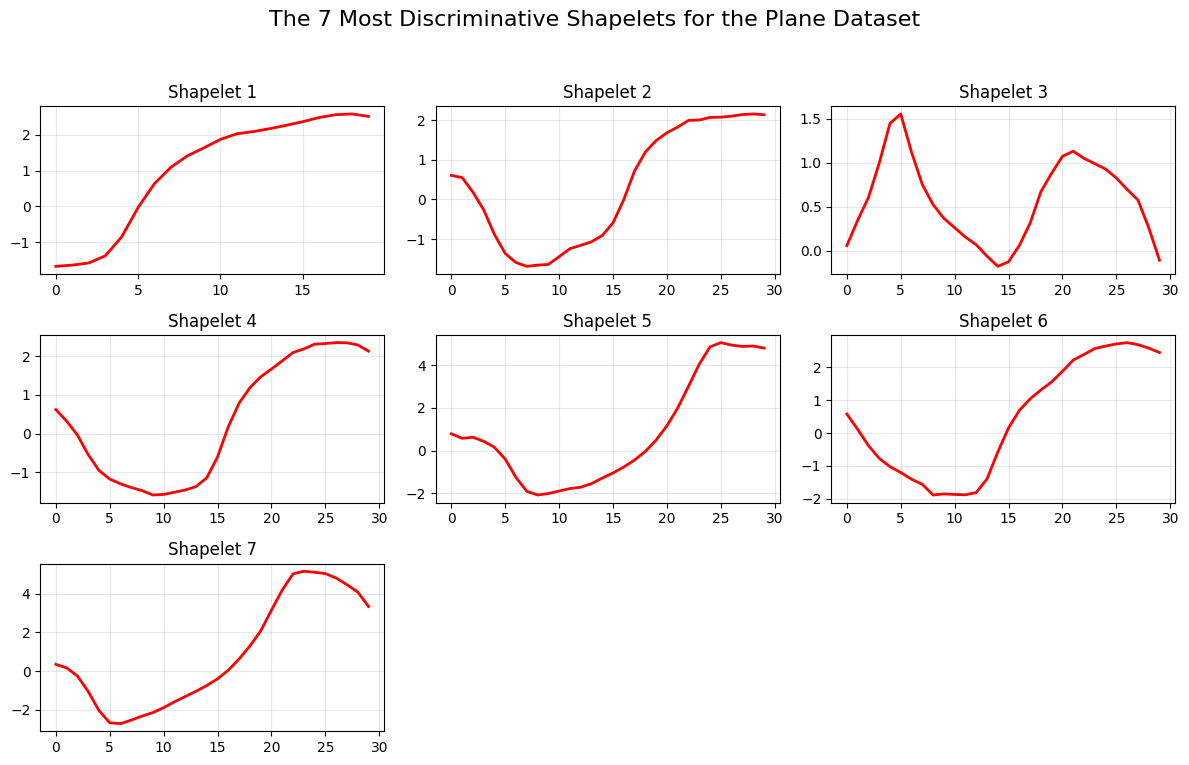

In [ ]:
import matplotlib.pyplot as plt

shapelet_mod = ShapeletTransform(n_shapelets=7, window_sizes=[10, 20, 30], random_state=42)
shapelet_mod.fit(X_train_2d, y_train)


plt.figure(figsize=(12, 8))

for i, shapelet in enumerate(shapelet_mod.shapelets_):
    plt.subplot(3, 3, i + 1)
    plt.plot(shapelet, color='red', linewidth=2)
    plt.title(f"Shapelet {i+1}")


plt.suptitle("The 7 Most Discriminative Shapelets for the Plane Dataset", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

### 1.2.2 Classification task with NN


In [ ]:
from tslearn.datasets import UCR_UEA_datasets
from tslearn.preprocessing import TimeSeriesScalerMinMax
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Conv1D, GlobalAveragePooling1D, Dense

In [ ]:
X_train, y_train, X_test, y_test = UCR_UEA_datasets().load_dataset("Plane")
label_mapping = {l: i for i, l in enumerate(np.unique(y_train))}
y_train = np.array([label_mapping[l] for l in y_train])
y_test = np.array([label_mapping[l] for l in y_test])


# Preprocessing for NNs 
scaler = TimeSeriesScalerMinMax()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


input_shape = (X_train_scaled.shape[1], 1) 
num_classes = 7


In [ ]:
def get_models(input_shape, num_classes):
    """
    input_shape: (144, 1) - sequence length and features.
    num_classes: 7 - for the Trace dataset.
    """
    models = {}
    
    # SimpleRNN The baseline model
    models['SimpleRNN'] = Sequential([
        SimpleRNN(32, input_shape=input_shape),
        Dense(num_classes, activation='softmax')
    ])
    
    # LSTM
    models['LSTM'] = Sequential([
        LSTM(32, input_shape=input_shape),
        Dense(num_classes, activation='softmax')
    ])
    
    # GRU
    models['GRU'] = Sequential([
        GRU(32, input_shape=input_shape),
        Dense(num_classes, activation='softmax')
    ])
    
    #1DCNN
    models['CNN'] = Sequential([
        Conv1D(32, kernel_size=3, activation='relu', input_shape=input_shape),
        Conv1D(64, kernel_size=3, activation='relu'),
        GlobalAveragePooling1D(),
        Dense(num_classes, activation='softmax')
    ])
    
    return models



/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



========== Training SimpleRNN ==========
------------------------------
Model: SimpleRNN
Final Training Accuracy:   0.5048
Final Validation Accuracy: 0.6857
Final Test Loss:           0.9907
------------------------------


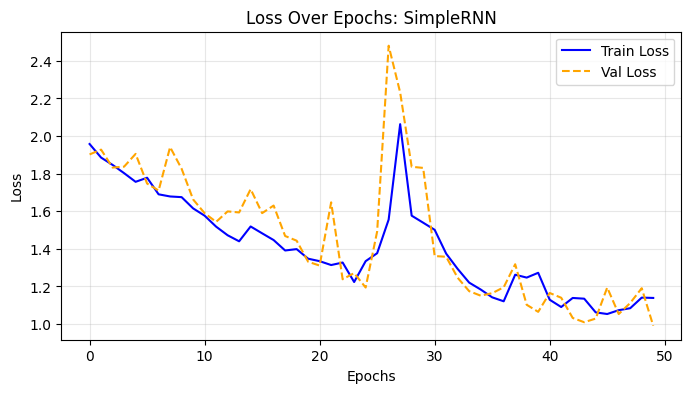


========== Training LSTM ==========
------------------------------
Model: LSTM
Final Training Accuracy:   0.1905
Final Validation Accuracy: 0.0952
Final Test Loss:           1.9924
------------------------------


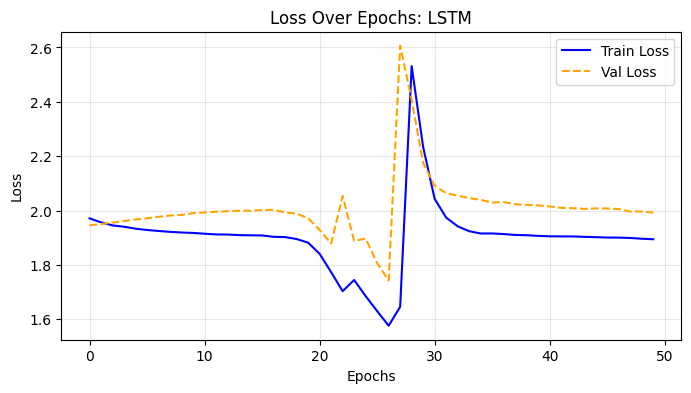


========== Training GRU ==========
------------------------------
Model: GRU
Final Training Accuracy:   0.1905
Final Validation Accuracy: 0.3810
Final Test Loss:           1.6593
------------------------------


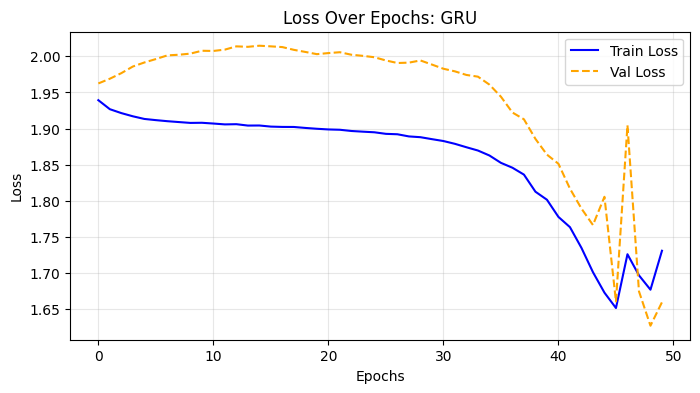


========== Training CNN ==========
------------------------------
Model: CNN
Final Training Accuracy:   0.3429
Final Validation Accuracy: 0.2286
Final Test Loss:           1.9133
------------------------------


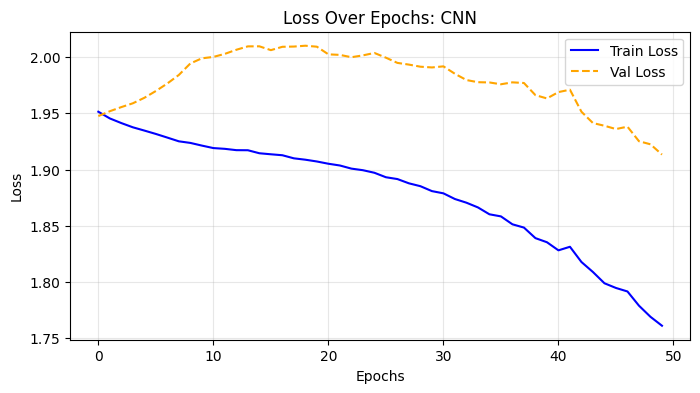

In [ ]:
results = {}
models = get_models(input_shape, num_classes)

for name, model in models.items():
    print(f"\n{'='*10} Training {name} {'='*10}")
    
    model.compile(optimizer='adam', 
                  loss='sparse_categorical_crossentropy', 
                  metrics=['accuracy'])
    
    with tf.device('/GPU:0'):
        # We store the training history to plot it later
        history = model.fit(
            X_train_scaled, y_train, 
            epochs=50, 
            batch_size=16, 
            validation_data=(X_test_scaled, y_test), 
            verbose=0
        )
    
    # --- 1. Print Final Scores ---
    test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
    train_acc = history.history['accuracy'][-1]
    
    print("-" * 30)
    print(f"Model: {name}")
    print(f"Final Training Accuracy:   {train_acc:.4f}")
    print(f"Final Validation Accuracy: {test_acc:.4f}")
    print(f"Final Test Loss:           {test_loss:.4f}")
    print("-" * 30)
    
    # --- 2. Plot Loss Curves ---
    plt.figure(figsize=(8, 4))
    plt.plot(history.history['loss'], label='Train Loss', color='blue')
    plt.plot(history.history['val_loss'], label='Val Loss', color='orange', linestyle='--')
    plt.title(f'Loss Over Epochs: {name}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    results[name] = test_acc


#### Performa Comparision of Neural Models

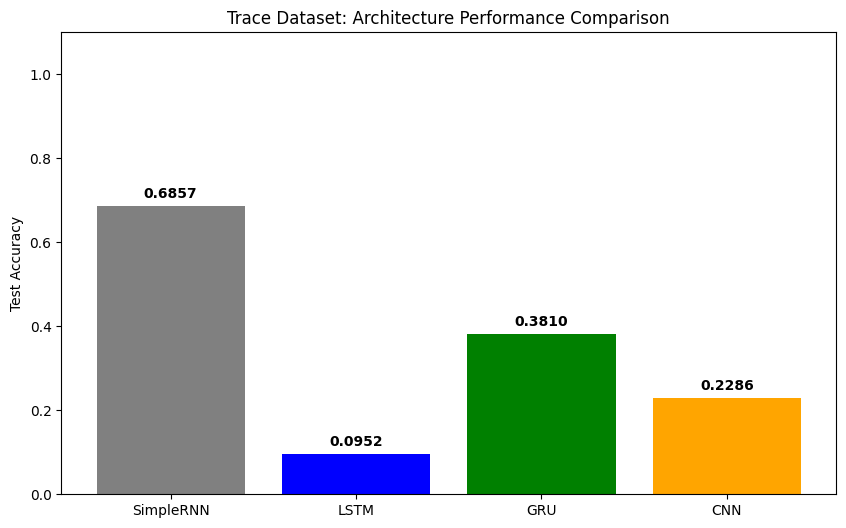

In [ ]:
# Assuming 'results' dictionary from the previous step exists
names = list(results.keys())
values = list(results.values())

plt.figure(figsize=(10, 6))
bars = plt.bar(names, values, color=['gray', 'blue', 'green', 'orange'])
plt.ylim(0, 1.1)
plt.ylabel("Test Accuracy")
plt.title("Trace Dataset: Architecture Performance Comparison")

# Add text labels on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f"{yval:.4f}", ha='center', fontweight='bold')

plt.show()

## 1.3 Other Tasks

### Clustering 

In [ ]:
from tslearn.clustering import TimeSeriesKMeans
from tslearn.datasets import UCR_UEA_datasets
from tslearn.preprocessing import TimeSeriesScalerMinMax


X_train, y_train, X_test, y_test = UCR_UEA_datasets().load_dataset("Plane")
X = np.concatenate((X_train, X_test))
X = TimeSeriesScalerMinMax().fit_transform(X)

n_clusters = 7


#  Euclidean K-Means
print("Running Euclidean K-Means...")
km_euc = TimeSeriesKMeans(n_clusters=n_clusters, metric="euclidean", random_state=42)
y_pred_euc = km_euc.fit_predict(X)


# 3. DTW K-Means
print("Running DTW K-Means (this may take a moment)...")
km_dtw = TimeSeriesKMeans(n_clusters=n_clusters, metric="dtw", random_state=42)
y_pred_dtw = km_dtw.fit_predict(X)

# 4. Visualization Function
def plot_clusters(model, predictions, data, title):
    plt.figure(figsize=(16, 4))
    for i in range(n_clusters):
        plt.subplot(1, n_clusters, i + 1)
        # Plot members of the cluster
        for series in data[predictions == i]:
            plt.plot(series.ravel(), "k-", alpha=0.1)
        # Plot the centroid
        plt.plot(model.cluster_centers_[i].ravel(), "r-", linewidth=3)
        plt.title(f"Cluster {i+1}")
        plt.grid(True)
    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

plot_clusters(km_euc, y_pred_euc, X, "Euclidean K-Means Centroids")
plot_clusters(km_dtw, y_pred_dtw, X, "DTW K-Means Centroids (DBA)")

## Atention model

In [ ]:
from sklearn.utils import shuffle
X_train, y_train, X_test, y_test = UCR_UEA_datasets().load_dataset("Plane")

X_all = np.concatenate((X_train, X_test), axis=0)
y_all = np.concatenate((y_train, y_test), axis=0)



X_shuffled, y_shuffled = shuffle(X_all, y_all, random_state=42)

if y_shuffled.min() == 1:
    y_shuffled = y_shuffled - 1

scaler = StandardScaler()
X_shuffled = scaler.fit_transform(X_shuffled.reshape(-1, 144)).reshape(-1, 144, 1)


print(f"Total Samples: {X_shuffled.shape[0]}")
print(f"Sequence Length: {X_shuffled.shape[1]}")
print(f"Number of classes: {len(np.unique(y_shuffled))}")

Total Samples: 210
Sequence Length: 144
Number of classes: 7


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_advanced_attention_model(input_shape, num_classes):
    inputs = layers.Input(shape=input_shape)
    
    # 1. Feature Extraction: LSTM
    # We use return_sequences=True to feed the attention layer a representation of every time step
    x = layers.LSTM(64, return_sequences=True)(inputs)
    
    # 2. Global Context: Multi-Head Self-Attention
    # This identifies which parts of the 275-step signal are most important for the class
    attention_out = layers.MultiHeadAttention(num_heads=4, key_dim=64)(query=x, value=x)
    
    # 3. Aggregation
    x = layers.GlobalAveragePooling1D()(attention_out)
    
    # 4. Classification Head
    x = layers.Dense(64, activation='relu')(x)
    
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    
    model = models.Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer='adam', 
                  loss='sparse_categorical_crossentropy', 
                  metrics=['accuracy'])
    return model


# --- PREPROCESSING ---
# 1. Shift labels if they start at 1
y_clean = y_shuffled.copy()
if y_clean.min() == 1:
    y_clean = y_clean - 1

# 2. Scale features (Critical for LSTM stability)
scaler = StandardScaler()
# We flatten to (N, 275), scale, then reshape back to (N, 275, 1)
X_scaled = scaler.fit_transform(X_shuffled.squeeze()).reshape(-1, 144, 1)

# --- MODEL RE-BUILD ---
model = build_advanced_attention_model((144, 1), 7)


print("Training Keras Atention Model on Place Data...")
# If GPU still fails, change the next line to: with tf.device('/CPU:0'):
with tf.device('/GPU:0'): 
    history = model.fit(
    X_scaled, y_clean,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)



# --- FINAL EVALUATION ---
val_size = int(len(X_scaled) * 0.2)
X_val, y_val = X_scaled[-val_size:], y_clean[-val_size:]

test_results = model.evaluate(X_val, y_val, verbose=0)
print("-" * 30)
print(f"Final Training Accuracy:   {history.history['accuracy'][-1]:.4f}")
print(f"Final Validation Accuracy: {history.history['val_accuracy'][-1]:.4f}")
print(f"Final Test Accuracy:       {test_results[1]:.4f}")
print("-" * 30)

Training Keras Atention Model on Place Data...
------------------------------
Final Training Accuracy:   0.1369
Final Validation Accuracy: 0.1667
Final Test Accuracy:       0.1667
------------------------------
